> **Ders oturumu kaydı:** Bu defter 21.10.2026 dersinde canlı yazılan kodları içerir. Hatalı hücreler bilerek düzeltilmeden bırakılmıştır.

# CENG468 Veri Madenciliği · Hafta 6
## Sepet analizi: bunu alan şunu da aldı
Öğr. Gör. Dr. Duygu TOPALOĞLU · 2026-2027 Güz

---
### Bu derste nasıl çalışacağız?
İşaretler geçen haftakiyle aynı:

| İşaret | Ne yapıyorsun? |
|---|---|
| 🔮 **Tahmin et** | Çalıştırmadan önce çıktıyı tahmin et ve yaz. |
| 🔧 **Değiştir** | Çalışan kodu küçük bir farkla uyarla. |
| ✍️ **Kendin yaz** | Boş hücreye kodu kendin yaz. Kopyala-yapıştır yok. |
| 🐞 **Hata avı** | Kod bilerek hatalı. Hata mesajını oku, nedenini bul, düzelt. |
| 🧩 **Sırala** | Karışık verilen satırları doğru sıraya koy. |
| 🕵️ **İz sür** | Tuhaf bir sonucun nedenini veride bul. |

**İpuçları:** Önce en az bir kez kendin dene, takılırsan yalnızca bir sonraki 💡 kutuyu aç.

**Renkli kutular** (H05 İlk Öneri Çözümleri defterindeki gibi):

<table>
<tr><td style="background:#e8f5e9; color:#1a1a1a; border-left:6px solid #2e7d32"><b>🎯 Ne elde ettik?</b></td><td>Adımdan çıkan sonuç. Not alacağın yer.</td></tr>
<tr><td style="background:#e3f2fd; color:#1a1a1a; border-left:6px solid #1565c0"><b>🔍 Nasıl düşünmeli?</b></td><td>Sonuca hangi sırayla, hangi soruyla varılır.</td></tr>
<tr><td style="background:#fff3e0; color:#1a1a1a; border-left:6px solid #ef6c00"><b>⚠️ Dikkat</b></td><td>Kolayca gözden kaçan bir tuzak.</td></tr>
<tr><td style="background:#ffebee; color:#1a1a1a; border-left:6px solid #c62828"><b>📌 Asıl ders</b></td><td>Dersin ana fikri.</td></tr>
<tr><td style="background:#f3e5f5; color:#1a1a1a; border-left:6px solid #6a1b9a"><b>🧭 Karar senin</b></td><td>Verinin değil, analistin vereceği karar.</td></tr>
</table>

**🔓 Kapalı kutular:** Bir görevin cevabını açık eden açıklamalar kapalı duruyor. **Önce görevi yap ya da soruyu tartış**, sonra aç.

**Kod nasıl okunur?** Hazır verilen kod hücrelerinde satırlar `# 1)`, `# 2)` gibi **adım etiketleriyle** bölünmüş. Her etiket, o satırların **ne amaçla** yazıldığını söyler. Kodu okurken önce etiketleri oku: "bu hücre ne yapmaya çalışıyor?" Sonra satırlara geç. Hücrenin altındaki **Kod ne yapıyor?** kısmı aynı adımları açıklar.

Bugünün yolu: **temiz tabloyu yeniden kur → satırdan sepete → elle destek (support), güven (confidence), kaldıraç (lift) → gerçek veride bir kural → neden Apriori? → mlxtend ile kurallar → kuraldan öneriye.**

**Takıldığında:** Her görevin altında bir **🔓 Çözdükten sonra aç** kutusu var: doğru kod, beklenen çıktı ve kısa açıklama. Önce kendin dene; takılırsan ya da sonucun farklıysa kutuyu aç ve karşılaştır.

---
## Bölüm 0: Veri hazırlığı, geçen haftanın özeti (20 dk)
Sepet analizine temiz bir tabloyla başlamamız gerekiyor. Geçen hafta bu tabloyu adım adım kurduk. Burada aynı işi **dört kod bloğunda** toplu olarak yapıyoruz:

| Blok | Ne yapıyor? | Ayrıntısı nerede? |
|---|---|---|
| 0.1 | Ham veriyi oku | H05 Bölüm 0 |
| 0.2 | Veriyi tanı: tuhaf satırlar nerede? | H05 Bölüm 1–2 · İlk Öneri Çözümleri **B1–B4** |
| 0.3 | Temizle ve denetle | H05 Bölüm 3 · İlk Öneri Çözümleri **B5** |
| 0.4 | Temiz tabloyu kaydet | H05 Bölüm 3 |

> Bu blokları her açılışta **sırayla** çalıştır. Defter her seferinde ham veriden başlar; geçen haftanın defterini bitirmemiş olsan da sorun olmaz. "**Neden** bu satırları sildik?" sorusunun ayrıntılı cevabı `Kodlar/CENG468_H05_Ilk_Oneri_Cozumler.ipynb` defterinde.

### 0.1 Ham veriyi oku

In [25]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# Grafiklerde kullanacağımız renkler
YESIL, KIRMIZI, MAVI, GRI, TURUNCU, MOR = "#2e7d32", "#c62828", "#1565c0", "#9e9e9e", "#ef6c00", "#6a1b9a"

VERI = "Veri/online_retail"
XLSX = os.path.join(VERI, "online_retail_II.xlsx")
CSV = os.path.join(VERI, "online_retail_2010_2011.csv")
TEMIZ = os.path.join(VERI, "online_retail_temiz.csv")

if os.path.exists(CSV):
    df = pd.read_csv(CSV, dtype={"Invoice": str, "StockCode": str},
                     parse_dates=["InvoiceDate"])
elif os.path.exists(XLSX):
    df = pd.read_excel(XLSX, sheet_name="Year 2010-2011",
                       dtype={"Invoice": str, "StockCode": str})
    df.to_csv(CSV, index=False)
else:
    raise FileNotFoundError(
        "Veri dosyası bulunamadı: " + os.path.abspath(XLSX)
        + "\nVeri/online_retail/BENIOKU.md dosyasındaki adımları izle.")

print("Ham veri (satır, sütun):", df.shape)

Ham veri (satır, sütun): (541910, 8)


### 0.2 Veriyi tanı: tuhaf satırlar nerede?
Temizlemeden önce **neyi neden** temizleyeceğimizi görelim. Aşağıdaki hücre geçen hafta bulduğumuz tuhaflıkları tek bir özet tabloda sayar.

In [26]:
kod_deseni = (df["StockCode"].str.replace(r"[0-9]", "9", regex=True)
                             .str.replace(r"[A-Za-z]", "A", regex=True))

ozet = pd.DataFrame({
    "satir_sayisi": {
        "Fatura 'C' ile başlıyor (iptal)":         df["Invoice"].str.startswith("C").sum(),
        "Fatura 'A' ile başlıyor (alacak düzeltmesi)": df["Invoice"].str.startswith("A").sum(),
        "Adet sıfır ya da eksi":                   (df["Quantity"] <= 0).sum(),
        "Fiyat sıfır ya da eksi":                  (df["Price"] <= 0).sum(),
        "Ürün kodu harfle başlıyor":               (~df["StockCode"].str[0].str.isdigit()).sum(),
        "Bütün sütunları aynı (tekrar)":           df.duplicated().sum(),
        "Müşteri numarası boş":                    df["Customer ID"].isnull().sum(),
    }
})
ozet["yuzde"] = (100 * ozet["satir_sayisi"] / len(df)).round(2)
print(ozet)
print("\nEn sık 5 ürün kodu deseni (9 = rakam, A = harf):")
print(kod_deseni.value_counts().head())

                                             satir_sayisi  yuzde
Fatura 'C' ile başlıyor (iptal)                      9288   1.71
Fatura 'A' ile başlıyor (alacak düzeltmesi)             3   0.00
Adet sıfır ya da eksi                               10624   1.96
Fiyat sıfır ya da eksi                               2517   0.46
Ürün kodu harfle başlıyor                            2996   0.55
Bütün sütunları aynı (tekrar)                        5268   0.97
Müşteri numarası boş                               135080  24.93

En sık 5 ürün kodu deseni (9 = rakam, A = harf):
StockCode
99999     487036
99999A     51488
AAAA        1277
A            715
AAA          710
Name: count, dtype: int64


Aynı tabloyu grafikte görelim (müşteri numarası satırı hariç; onu silmiyoruz):

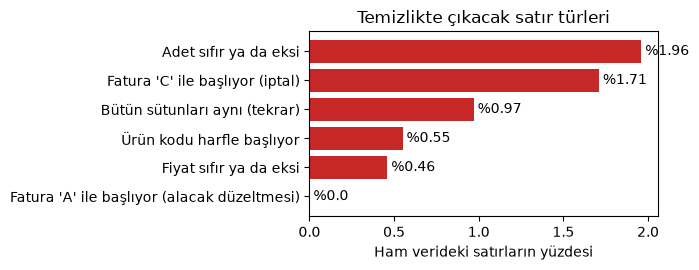

In [27]:
silinecek = ozet.drop("Müşteri numarası boş")["yuzde"].sort_values()
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.barh(silinecek.index, silinecek.values, color=KIRMIZI)
ax.set_xlabel("Ham verideki satırların yüzdesi")
ax.set_title("Temizlikte çıkacak satır türleri")
for i, v in enumerate(silinecek.values):
    ax.text(v, i, f" %{v}", va="center")
plt.tight_layout()
plt.show()

**Tabloyu okurken:**
- Satırlar **birbirinden bağımsız değil**. Bir iptal satırının adedi de eksidir; aynı satır hem birinci hem üçüncü satırda sayılır. Bu yüzden yüzdeler toplanmaz.
- **Müşteri numarası boş** satırları silmiyoruz. Bugünkü soru "aynı faturada hangi ürünler birlikte?"; bunun için müşteriyi bilmek gerekmiyor, faturayı bilmek yeterli.
- Kod desenleri tablosunda `99999` normal ürün kodu, `99999A` aynı ürünün bir çeşidi; harfle başlayan desenler (`AAAA` = `POST` gibi) kargo, komisyon ve düzeltme kayıtları.

### 0.3 Temizle ve denetle
Her satır bir sınıf kararı. Her karar bir **maske**: tutmak istediğimiz satırlar `True`. `adim()` her adımda kaç satır çıktığını yazar.

In [28]:
def adim(veri, maske, aciklama):
    """Maskesi True olan satırları tutar; kaç satır çıktığını yazar."""
    sonra = veri[maske]
    print(f"{aciklama:<30} çıkan: {len(veri) - len(sonra):>7,}   kalan: {len(sonra):>7,}")
    return sonra


d = df.copy()
d = adim(d, ~d["Invoice"].str.startswith("C"), "İptal faturalar")         # satış değil, iptal
d = adim(d, ~d["Invoice"].str.startswith("A"), "'A' faturalar")           # muhasebe düzeltmesi
d = adim(d, d["Quantity"] > 0, "Adet sıfır ya da eksi")                   # stok düzeltmeleri
d = adim(d, d["Price"] > 0, "Fiyat sıfır ya da eksi")                     # para el değiştirmemiş
d = adim(d, d["StockCode"].str[0].str.isdigit(), "Ürün dışı kodlar")      # kargo, komisyon, indirim
d = adim(d, ~d.duplicated(), "Tekrarlı satırlar")                         # kayıt tekrarı
df_temiz = d

# Denetim: her kural gerçekten uygulandı mı?
testler = {
    "İptal ('C') fatura yok":      not df_temiz["Invoice"].str.startswith("C").any(),
    "Düzeltme ('A') faturası yok": not df_temiz["Invoice"].str.startswith("A").any(),
    "Bütün adetler > 0":           (df_temiz["Quantity"] > 0).all(),
    "Bütün fiyatlar > 0":          (df_temiz["Price"] > 0).all(),
    "Ürün dışı kod yok":           df_temiz["StockCode"].str[0].str.isdigit().all(),
    "Tekrarlı satır yok":          not df_temiz.duplicated().any(),
}
print()
for ad, sonuc in testler.items():
    print("✅" if sonuc else "❌", ad)

İptal faturalar                çıkan:   9,288   kalan: 532,622
'A' faturalar                  çıkan:       3   kalan: 532,619
Adet sıfır ya da eksi          çıkan:   1,336   kalan: 531,283
Fiyat sıfır ya da eksi         çıkan:   1,179   kalan: 530,104
Ürün dışı kodlar               çıkan:   2,379   kalan: 527,725
Tekrarlı satırlar              çıkan:   5,221   kalan: 522,504

✅ İptal ('C') fatura yok
✅ Düzeltme ('A') faturası yok
✅ Bütün adetler > 0
✅ Bütün fiyatlar > 0
✅ Ürün dışı kod yok
✅ Tekrarlı satır yok


> ⚠️ **Bu temiz tablonun bilinen iki sınırı var** (ayrıntısı İlk Öneri Çözümleri E4 ve E8'de):
> 1. **İptal edilen satışlar tabloda duruyor.** İptal satırlarını sildik, ama onların iptal ettiği satışları bıraktık. Örneğin 80.995 adetlik *PAPER CRAFT, LITTLE BIRDIE* siparişi 12 dakika sonra iptal edilmiş, ama temiz tabloda satış olarak görünüyor.
> 2. **Sepetler eşit büyüklükte değil.** 50'den fazla ürün içeren sepetler, sepetlerin yaklaşık %11'i; ama bütün ürün çiftlerinin yaklaşık %88'ini bu sepetler üretiyor.
>
> Bugün tabloyu bu hâliyle kullanacağız. Sonuçları okurken bu iki sınırı aklında tut.

### 0.4 Temiz tabloyu kaydet
Temiz tabloyu bir dosyaya da yazıyoruz; ileriki haftalarda başka defterler bu dosyayı kullanabilir.

In [29]:
df_temiz.to_csv(TEMIZ, index=False)
print("Kaydedildi:", TEMIZ)
print(f"Temiz tablo: {len(df_temiz):,} satır · {df_temiz['Invoice'].nunique():,} fatura (sepet) · "
      f"{df_temiz['StockCode'].nunique():,} ürün")

Kaydedildi: Veri/online_retail/online_retail_temiz.csv
Temiz tablo: 522,504 satır · 19,773 fatura (sepet) · 3,900 ürün


<div style="background:#e8f5e9; color:#1a1a1a; border-left:6px solid #2e7d32; padding:10px 16px; border-radius:6px; margin:8px 0">

<b style="color:#2e7d32; font-size:1.05em">🎯 Ne elde ettik?</b>

- Ham veride yaklaşık **542 bin** satır vardı; temiz tabloda yaklaşık **522 bin** satır kaldı. Silinen satırların her birinin bir gerekçesi var (0.3'teki yorum satırları).
- Bugünün birimi **fatura = sepet**. Temiz tabloda yaklaşık **20 bin sepet** ve **4 bin ürün** var. Bölüm 1'de bu iki sayı, kuracağımız tablonun boyutunu belirleyecek.

</div>

---
## Bölüm 1: Satırdan sepete (20 dk)
Geçen hafta "en popüler" sorusunu **ürün** açısından sorduk. Sepet analizinde soru **fatura** açısından: *aynı faturada hangi ürünler birlikte?*

Önce sunumdaki **üç gerçek faturayla** başlayalım (12–13. slayt): 537139, 540777 ve 542220.

In [30]:
# Sunumdaki üç fatura: temiz tablodan yalnızca bu üç faturanın satırlarını al
uc_fatura = ["537139", "540777", "542220"]
mini = df_temiz[df_temiz["Invoice"].isin(uc_fatura)][["Invoice", "Description", "Quantity"]]
mini

,Invoice,Description,Quantity
8584,537139,REGENCY CAKESTAND 3 TIER,1
8585,537139,CHRISTMAS GINGHAM HEART,12
8586,537139,HEART WOODEN CHRISTMAS DECORATION,12
52376,540777,REGENCY CAKESTAND 3 TIER,5
52377,540777,GREEN REGENCY TEACUP AND SAUCER,8
52378,540777,ROSES REGENCY TEACUP AND SAUCER,8
71945,542220,"SET 3 RETROSPOT TEA,COFFEE,SUGAR",24
71946,542220,REGENCY CAKESTAND 3 TIER,6
71947,542220,RED RETROSPOT CAKE STAND,3


Sepet analizi için bu tabloyu **sepet tablosuna** çevireceğiz: her satır bir fatura, her sütun bir ürün, hücrede "bu faturada bu ürün var mı?" (`True`/`False`).

Bu dönüşüme **uzun tablodan geniş tabloya** geçiş denir. Uzun tabloda her **satış kalemi** bir satırdır; geniş tabloda her **sepet** bir satırdır (ürün adları kısaltıldı):

<table>
<tr><td style="vertical-align:middle; text-align:center"><b>Uzun tablo</b><br>(bir satır = bir kalem)</td><td></td><td style="vertical-align:middle; text-align:center"><b>Geniş tablo</b><br>(bir satır = bir sepet)</td></tr>
<tr>
<td>
<table>
<tr style="background:#37474f; color:#ffffff"><th>Invoice</th><th>Ürün</th></tr>
<tr style="background:#fbe5d6; color:#1a1a1a"><td>537139</td><td>REGENCY CAKESTAND</td></tr>
<tr style="background:#fbe5d6; color:#1a1a1a"><td>537139</td><td>GINGHAM HEART</td></tr>
<tr style="background:#fbe5d6; color:#1a1a1a"><td>537139</td><td>WOODEN HEART</td></tr>
<tr style="background:#deebf7; color:#1a1a1a"><td>540777</td><td>REGENCY CAKESTAND</td></tr>
<tr style="background:#deebf7; color:#1a1a1a"><td>540777</td><td>GREEN TEACUP</td></tr>
<tr style="background:#deebf7; color:#1a1a1a"><td>540777</td><td>ROSES TEACUP</td></tr>
<tr style="background:#e2f0d9; color:#1a1a1a"><td>542220</td><td>RETROSPOT SET</td></tr>
<tr style="background:#e2f0d9; color:#1a1a1a"><td>542220</td><td>REGENCY CAKESTAND</td></tr>
<tr style="background:#e2f0d9; color:#1a1a1a"><td>542220</td><td>RETROSPOT CAKE STAND</td></tr>
</table>
</td>
<td style="vertical-align:middle; font-size:2em">➜</td>
<td>
<table>
<tr style="background:#37474f; color:#ffffff"><th>Invoice</th><th>REGENCY</th><th>GINGHAM</th><th>WOODEN</th><th>GREEN</th><th>ROSES</th><th>R. SET</th><th>R. STAND</th></tr>
<tr style="background:#fbe5d6; color:#1a1a1a"><td>537139</td><td>?</td><td>?</td><td>?</td><td>?</td><td>?</td><td>?</td><td>?</td></tr>
<tr style="background:#deebf7; color:#1a1a1a"><td>540777</td><td>?</td><td>?</td><td>?</td><td>?</td><td>?</td><td>?</td><td>?</td></tr>
<tr style="background:#e2f0d9; color:#1a1a1a"><td>542220</td><td>?</td><td>?</td><td>?</td><td>?</td><td>?</td><td>?</td><td>?</td></tr>
</table>
</td>
</tr>
</table>

Aynı renkteki satırlar **aynı sepete** ait. Soldaki üç renkli grup, sağda birer satıra dönüşüyor.

**🔮 Tahmin et:** Sağdaki tablonun `?` hücrelerini elle doldur (var = True, yok = False). Sonra aşağıdaki üç hücreyi sırayla çalıştır.

*Tahminim:* ...

In [31]:
# Adım 1: her (fatura, ürün) çifti için toplam adet
adim1 = mini.groupby(["Invoice", "Description"])["Quantity"].sum()
adim1

Invoice  Description                      
537139   CHRISTMAS GINGHAM HEART              12
         HEART WOODEN CHRISTMAS DECORATION    12
         REGENCY CAKESTAND 3 TIER              1
540777   GREEN REGENCY TEACUP AND SAUCER       8
         REGENCY CAKESTAND 3 TIER              5
         ROSES REGENCY TEACUP AND SAUCER       8
542220   RED RETROSPOT CAKE STAND              3
         REGENCY CAKESTAND 3 TIER              6
         SET 3 RETROSPOT TEA,COFFEE,SUGAR     24
Name: Quantity, dtype: int64

**Kod ne yapıyor?**
- `groupby(["Invoice", "Description"])`: Geçen hafta tek sütuna göre gruplamıştık. Bu kez **iki sütuna birden** göre grupluyoruz: her (fatura, ürün) **çifti** bir grup.
- `["Quantity"].sum()`: Aynı faturada aynı ürün iki ayrı satırda geçiyorsa adetleri toplar.
- Sonuç bir Series, ama index'i **iki katlı**: solda önce Invoice, sonra Description. Çıktıda fatura numarasının her grubun yalnızca ilk satırında yazdığına dikkat et.

Şimdi `unstack()`: iki katlı index'in **ikinci katını** (Description) alıp sütunlara çevirir. Bir faturada olmayan ürünün hücresi boş kalırdı; `fill_value=0` oraya 0 yazar.

In [32]:
# Adım 2: ürünleri sütunlara aç
adim2 = adim1.unstack(fill_value=0)
adim2

Description,CHRISTMAS GINGHAM HEART,GREEN REGENCY TEACUP AND SAUCER,HEART WOODEN CHRISTMAS DECORATION,RED RETROSPOT CAKE STAND,REGENCY CAKESTAND 3 TIER,ROSES REGENCY TEACUP AND SAUCER,"SET 3 RETROSPOT TEA,COFFEE,SUGAR"
Invoice,,,,,,,
537139,12,0,12,0,1,0,0
540777,0,8,0,0,5,8,0
542220,0,0,0,3,6,0,24


**🔮 Tahmin et:** `adim2 > 0` ne verir? Hücre türü ne olur?

*Tahminim:* ...

In [33]:
# Adım 3: "var mı?" sorusuna çevir
sepet_mini = adim2 > 0
sepet_mini

Description,CHRISTMAS GINGHAM HEART,GREEN REGENCY TEACUP AND SAUCER,HEART WOODEN CHRISTMAS DECORATION,RED RETROSPOT CAKE STAND,REGENCY CAKESTAND 3 TIER,ROSES REGENCY TEACUP AND SAUCER,"SET 3 RETROSPOT TEA,COFFEE,SUGAR"
Invoice,,,,,,,
537139,True,False,True,False,True,False,False
540777,False,True,False,False,True,True,False
542220,False,False,False,True,True,False,True


<details><summary><b>🔓 Çözdükten (ya da tartıştıktan) sonra aç</b></summary>

<div style="background:#e8f5e9; color:#1a1a1a; border-left:6px solid #2e7d32; padding:10px 16px; border-radius:6px; margin:8px 0">

<b style="color:#2e7d32; font-size:1.05em">🎯 Tahminini kontrol et</b>

`adim2 > 0` her hücreyi bir soruya çevirir: "adet 0'dan büyük mü?" Sonuç **True/False** (bool) değerli bir tablo. Elle doldurduğun tablo şöyle olmalıydı:

| Invoice | REGENCY | GINGHAM | WOODEN | GREEN | ROSES | R. SET | R. STAND |
|---|---|---|---|---|---|---|---|
| 537139 | True | True | True | False | False | False | False |
| 540777 | True | False | False | True | True | False | False |
| 542220 | True | False | False | False | False | True | True |

Kodda sütunlar alfabetik sırayla çıkar ve adlar tam yazılır (ör. `ROSES REGENCY TEACUP AND SAUCER ` sonunda bir boşlukla). Her satırda tam üç True var: her faturada üç farklı ürün. REGENCY CAKESTAND üç sepette de var.

</div>

</details>

<div style="background:#e8f5e9; color:#1a1a1a; border-left:6px solid #2e7d32; padding:10px 16px; border-radius:6px; margin:8px 0">

<b style="color:#2e7d32; font-size:1.05em">🎯 Ne elde ettik?</b>

Üç adım, üç soru:

| Adım | Kod | Sorduğu soru |
|---|---|---|
| 1 | `groupby([...]).sum()` | Her sepette her üründen **kaç tane** var? |
| 2 | `.unstack(fill_value=0)` | Bunu **sepet × ürün** tablosu olarak göster. |
| 3 | `> 0` | Bu sepette bu ürün **var mı**? |

Elle doldurduğun tabloyla karşılaştır. Her faturada üç ürün var; her satırda üç `True` olmalı.

</div>

**Neden adet değil de True/False?** Sepet analizinde soru "kaç tane?" değil, "**var mı?**". 30 ekmek alan sepet ile 1 ekmek alan sepet, "ekmek içeren sepet" olarak aynı sayılır. (Geçen haftaki PAPER CRAFT hikâyesini hatırla: dev bir sipariş adetle sonucu bozabiliyordu.)

**🧩 Sırala:** Aşağıdaki parçaları doğru sıraya koyup **tek satırda** gerçek verinin sepet tablosunu kur. Sütunlar ürün adları (`Description`) olsun. Sonucu `sepet` değişkenine ata.

```
> 0
.unstack(fill_value=0)
df_temiz.groupby(["Invoice", "Description"])
["Quantity"].sum()
```

In [34]:
sepet = df_temiz.groupby(["Invoice", "Description"])["Quantity"].sum().unstack(fill_value=0) > 0

In [35]:
sepet.head()

Description,4 PURPLE FLOCK DINNER CANDLES,50'S CHRISTMAS GIFT BAG LARGE,DOLLY GIRL BEAKER,I LOVE LONDON MINI BACKPACK,I LOVE LONDON MINI RUCKSACK,NINE DRAWER OFFICE TIDY,OVAL WALL MIRROR DIAMANTE,RED SPOT GIFT BAG LARGE,SET 2 TEA TOWELS I LOVE LONDON,SPACEBOY BABY GIFT SET,...,ZINC STAR T-LIGHT HOLDER,ZINC SWEETHEART SOAP DISH,ZINC SWEETHEART WIRE LETTER RACK,ZINC T-LIGHT HOLDER STAR LARGE,ZINC T-LIGHT HOLDER STARS LARGE,ZINC T-LIGHT HOLDER STARS SMALL,ZINC TOP 2 DOOR WOODEN SHELF,ZINC WILLIE WINKIE CANDLE STICK,ZINC WIRE KITCHEN ORGANISER,ZINC WIRE SWEETHEART LETTER TRAY
Invoice,,,,,,,,,,,,,,,,,,,,,
536365,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
536366,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
536367,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
536368,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
536369,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [36]:
sepet.columns

Index([' 4 PURPLE FLOCK DINNER CANDLES', ' 50'S CHRISTMAS GIFT BAG LARGE',
       ' DOLLY GIRL BEAKER', ' I LOVE LONDON MINI BACKPACK',
       ' I LOVE LONDON MINI RUCKSACK', ' NINE DRAWER OFFICE TIDY',
       ' OVAL WALL MIRROR DIAMANTE ', ' RED SPOT GIFT BAG LARGE',
       ' SET 2 TEA TOWELS I LOVE LONDON ', ' SPACEBOY BABY GIFT SET',
       ...
       'ZINC STAR T-LIGHT HOLDER ', 'ZINC SWEETHEART SOAP DISH',
       'ZINC SWEETHEART WIRE LETTER RACK', 'ZINC T-LIGHT HOLDER STAR LARGE',
       'ZINC T-LIGHT HOLDER STARS LARGE', 'ZINC T-LIGHT HOLDER STARS SMALL',
       'ZINC TOP  2 DOOR WOODEN SHELF ', 'ZINC WILLIE WINKIE  CANDLE STICK',
       'ZINC WIRE KITCHEN ORGANISER', 'ZINC WIRE SWEETHEART LETTER TRAY'],
      dtype='str', name='Description', length=4005)

<details><summary>💡 İpucu 1</summary>

Küçük tablodaki üç adımı (groupby + sum → unstack → > 0) tek satırda art arda yaz.

</details>

<details><summary><b>🔓 Çözdükten (ya da tartıştıktan) sonra aç</b></summary>

<div style="background:#e3f2fd; color:#1a1a1a; border-left:6px solid #1565c0; padding:10px 16px; border-radius:6px; margin:8px 0">

<b style="color:#1565c0; font-size:1.05em">🔍 Doğru sıra</b>

```python
sepet = df_temiz.groupby(["Invoice", "Description"])["Quantity"].sum().unstack(fill_value=0) > 0
```
Sıra, küçük tablodaki üç adımın sırası: **1)** `df_temiz.groupby(["Invoice", "Description"])` gruplar, **2)** `["Quantity"].sum()` her grubun adedini toplar, **3)** `.unstack(fill_value=0)` ürünleri sütunlara açar, **4)** `> 0` "var mı?" sorusunu sorar. `> 0` en sonda olmalı: önce tablo kurulur, sonra her hücre True/False'a çevrilir.

Hücre hata vermeden çalışırsa çıktı görünmez (atama yaptık). Kontrol için bir sonraki hücredeki `sepet.shape`'i çalıştır.

</div>

</details>

**🔮 Tahmin et:** `sepet` tablosunun kaç satırı, kaç sütunu var? Satır = ?, sütun = ?

*Tahminim:* ...

In [37]:
sepet.shape

(19773, 4005)

**🔮 Düşün:** Bir faturada ortalama 26 farklı ürün var, medyanı 15 (geçen haftaki E8). Bir satırda 4.000'den fazla sütun varsa, hücrelerin yaklaşık yüzde kaçı `True`'dur? Bu tabloya **seyrek** denir.

In [38]:
print("Dolu hücre oranı (%):", sepet.values.mean() * 100)

Dolu hücre oranı (%): 0.6529439980230043


<details><summary><b>🔓 Çözdükten (ya da tartıştıktan) sonra aç</b></summary>

<div style="background:#e8f5e9; color:#1a1a1a; border-left:6px solid #2e7d32; padding:10px 16px; border-radius:6px; margin:8px 0">

<b style="color:#2e7d32; font-size:1.05em">🎯 Tahminini kontrol et</b>

- `sepet.shape` yaklaşık **(19.773, 4.005)** verir: 19.773 satır (**sepet**) ve 4.005 sütun (**ürün adı**). Bölüm 0'daki fatura sayısıyla aynı. Ürün sayısı ise 3.900 değil, 4.005: Sütunları **ürün adına** (`Description`) göre kurduk ve bazı ürün kodlarının birden çok adı var.
- Dolu hücre oranı yaklaşık **%0,65**. Yani tablonun **%99'dan fazlası `False`**. Ortalama bir sepette 26 ürün var; 4.000 sütunun 26'sı dolu demek, yaklaşık %0,65 demek.

</div>

</details>

Seyrekliği gözle görelim. Aşağıdaki hücre sepet tablosunun küçük bir köşesini çiziyor: en çok satan 60 ürün ve ilk 60 sepet. Her nokta bir `True`.

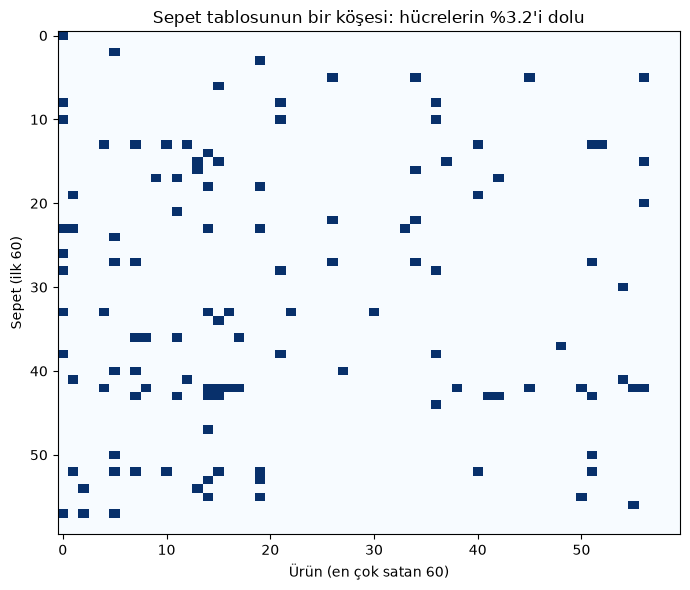

In [39]:
# 1) En çok sepette geçen 60 ürünü ve ilk 60 sepeti seç
en_sik = sepet.sum().nlargest(60).index
kose = sepet.loc[sepet.index[:60], en_sik]

# 2) True olan hücreleri koyu, False olanları açık çiz
fig, ax = plt.subplots(figsize=(7, 6))
ax.imshow(kose.values, cmap="Blues", aspect="auto", interpolation="nearest")
ax.set_xlabel("Ürün (en çok satan 60)")
ax.set_ylabel("Sepet (ilk 60)")
ax.set_title(f"Sepet tablosunun bir köşesi: hücrelerin %{100 * kose.values.mean():.1f}'i dolu")
plt.tight_layout()
plt.show()

Bu köşede bile hücrelerin çoğu boş; üstelik **en çok satan** ürünleri seçtik. Bütün tabloda boşluk oranı çok daha yüksek. Bu yüzden sepet analizinde asıl iş, bu dev ve boş tabloda **birlikte dolu olan** hücreleri bulmak.

---
## Bölüm 2: Destek, güven, kaldıraç (elle) (25 dk)
Sunumdaki dört ölçünün kodu. Formülleri sunumdaki gösterimle yazalım (N = sepet sayısı, Freq = kaç sepette görüldüğü):

| Ölçü | İngilizcesi (kodda) | Soru | Hesap |
|---|---|---|---|
| **Destek** | support | A, sepetlerin ne kadarında var? | Freq(A) / N |
| **Birlikte destek** | support | A ve B ne sıklıkla birlikte? | Freq(A, B) / N |
| **Güven** | confidence | A alanların ne kadarı B'yi de aldı? | Freq(A, B) / Freq(A) |
| **Kaldıraç** | lift | A'yı bilmek B olasılığını kaç katına çıkarıyor? | Support(A, B) / (Support(A) · Support(B)) |

**Hatırla:** Bir True/False sütununun **ortalaması**, `True` oranıdır (geçen hafta `iptal.mean()`). Yani Freq(A) / N = `tablo[A].mean()`.

<div style="background:#e3f2fd; color:#1a1a1a; border-left:6px solid #1565c0; padding:10px 16px; border-radius:6px; margin:8px 0">

<b style="color:#1565c0; font-size:1.05em">🔍 Nasıl düşünmeli?</b>

Üç ölçüyü üç soru gibi düşün. Sepetinde **A** olan bir müşteri kasaya geliyor:

1. **Destek (support):** "A ne kadar yaygın?" Bütün sepetlere bakarız.
2. **Güven (confidence):** "A'yı alanların ne kadarı B'yi de almış?" **Yalnızca A'lı sepetlere** bakarız.
3. **Kaldıraç (lift):** "A'yı bilmek, B tahminimizi ne kadar değiştirdi?" Güveni, B'nin **zaten** ne kadar yaygın olduğuyla karşılaştırırız.

Kaldıraç **1** ise A'yı bilmek hiçbir şey değiştirmemiş demektir. **1'den büyükse** A'lı sepetlerde B, beklenenden sık. **1'den küçükse** beklenenden seyrek.

</div>

Sunumdaki **8 sepeti** (18–19. slayt) kodla kuralım. Bölüm 1'deki dönüşümün aynısı: önce uzun tablo (her satır bir sepet–ürün çifti), sonra sepet × ürün, sonra "var mı?".

In [40]:
# 1) Sunumdaki 8 sepet
sepetler8 = {
    1: ["Ekmek", "Süt", "Kola", "Peynir"], 2: ["Ekmek", "Süt", "Kola"], 3: ["Ekmek", "Süt"], 4: ["Ekmek", "Soğan"],
    5: ["Un", "Süt", "Kola", "Peynir"],    6: ["Un", "Süt", "Kola"],    7: ["Un", "Süt"],    8: ["Un", "Soğan"],
}

# 2) Uzun tablo: her satır bir (sepet, ürün) çifti
uzun8 = pd.DataFrame([(no, urun) for no, urunler in sepetler8.items() for urun in urunler],
                     columns=["Sepet", "Urun"])

# 3) Bölüm 1'deki dönüşüm: sepet × ürün, "var mı?"
sepet8 = uzun8.groupby(["Sepet", "Urun"]).size().unstack(fill_value=0) > 0
sepet8

Urun,Ekmek,Kola,Peynir,Soğan,Süt,Un
Sepet,,,,,,
1,True,True,True,False,True,False
2,True,True,False,False,True,False
3,True,False,False,False,True,False
4,True,False,False,True,False,False
5,False,True,True,False,True,True
6,False,True,False,False,True,True
7,False,False,False,False,True,True
8,False,False,False,True,False,True


**Kod ne yapıyor?** Bölüm 1'de adetleri `sum()` ile topluyorduk; burada adet sütunu yok, her satır bir kez sayılsın diye `size()` kullandık. Sonrası aynı: `unstack` ürünleri sütunlara açar, `> 0` "var mı?" sorusunu sorar. Sütunlar alfabetik sırada (Ekmek, Kola, Peynir, Soğan, Süt, Un).

**🔮 Tahmin et:** `sepet8["Süt"].mean()` kaç verir? Sunumdaki tabloya bak: Süt kaç sepette var?

*Tahminim:* ...

In [41]:
sepet8["Süt"].mean()

np.float64(0.75)

<details><summary><b>🔓 Çözdükten (ya da tartıştıktan) sonra aç</b></summary>

<div style="background:#e8f5e9; color:#1a1a1a; border-left:6px solid #2e7d32; padding:10px 16px; border-radius:6px; margin:8px 0">

<b style="color:#2e7d32; font-size:1.05em">🎯 Tahminini kontrol et</b>

**0.75.** Süt 8 sepetin 6'sında var: Freq(Süt) / N = 6 / 8 = 0,75. `mean()` True'ları 1, False'ları 0 sayar; ortalama doğrudan True oranıdır.

</div>

</details>

İki ürünün **birlikte** olduğu sepetler: iki maskeyi `&` ile birleştir (geçen haftaki kural: her koşul kendi parantezinde).

**🔮 Tahmin et:** Kola ve Peynir'in birlikte desteği, Support(Kola, Peynir), kaç?

*Tahminim:* ...

In [42]:
(sepet8["Kola"] & sepet8["Peynir"]).mean()

np.float64(0.25)

**Kod ne yapıyor?** `sepet8["Kola"]` ve `sepet8["Peynir"]` iki maske. `&` iki maskeyi satır satır birleştirir: **ikisi de** `True` ise `True`. `.mean()` bu yeni maskenin `True` oranını verir: Kola ve Peynir'in **birlikte** bulunduğu sepetlerin oranı.

<details><summary><b>🔓 Çözdükten (ya da tartıştıktan) sonra aç</b></summary>

<div style="background:#e8f5e9; color:#1a1a1a; border-left:6px solid #2e7d32; padding:10px 16px; border-radius:6px; margin:8px 0">

<b style="color:#2e7d32; font-size:1.05em">🎯 Tahminini kontrol et</b>

**0.25.** Kola ve Peynir yalnız 1. ve 5. sepette birlikte: Freq(Kola, Peynir) / N = 2 / 8 = 0,25.

</div>

</details>

**✍️ Kendin yaz:** Üç fonksiyon yaz. Her biri bir sepet tablosu ve ürün adlarını alsın:
- `destek(tablo, a)` → A'nın desteği (support)
- `guven(tablo, a, b)` → A → B güveni (confidence)
- `kaldirac(tablo, a, b)` → A → B kaldıracı (lift)

İlk fonksiyon hazır; diğer ikisini yaz. Fonksiyonların birbirini kullanabilir.

In [43]:
def destek(tablo, a):
    return tablo[a].mean()


def guven(tablo, a, b):
    # Kodunu buraya yaz
    pass


def kaldirac(tablo, a, b):
    # Kodunu buraya yaz
    pass

<details><summary>💡 İpucu 1</summary>

Güven = birlikte destek / A'nın desteği. Birlikte desteği bir üstteki hücrede hesapladın.

</details>

<details><summary>💡 İpucu 2</summary>

Kaldıraç = güven / B'nin desteği. `guven(...)` ve `destek(...)` fonksiyonlarını çağırabilirsin.

</details>

<details><summary><b>🔓 Çözdükten (ya da tartıştıktan) sonra aç</b></summary>

<div style="background:#e3f2fd; color:#1a1a1a; border-left:6px solid #1565c0; padding:10px 16px; border-radius:6px; margin:8px 0">

<b style="color:#1565c0; font-size:1.05em">🔍 Bir çözüm ve neden böyle yazıldığı</b>

```python
def guven(tablo, a, b):
    birlikte = (tablo[a] & tablo[b]).mean()   # 1) A ve B birlikte: Support(A, B)
    return birlikte / destek(tablo, a)        # 2) A'lı sepetler içindeki payı: Support(A, B) / Support(A)

def kaldirac(tablo, a, b):
    return guven(tablo, a, b) / destek(tablo, b)   # Confidence(A → B) / Support(B)
```
- `guven`, `destek` fonksiyonunu; `kaldirac` da hem `guven` hem `destek` fonksiyonunu **çağırıyor**. Formülü bir kez yazıp tekrar kullanmak, aynı hesabı üç yerde yazıp üçünde de hata yapma riskini ortadan kaldırır.
- Fonksiyonların hiçbiri **sepet8**'e özgü değil: `tablo` diye bir parametre alıyorlar. Bölüm 3'te aynı fonksiyonları 20 bin sepetlik gerçek tabloya vereceğiz.
- Sık yapılan hata: güvende `destek(tablo, b)`'ye bölmek. Payda **öncülün** (A'nın) desteği olmalı; kaldıraçta ise **sonucun** (B'nin).

</div>

</details>

Fonksiyonlarını 8 sepette sına. Sonuçları sunumdaki **Sıra sizde** cevaplarıyla (27. slayt) karşılaştır.

In [44]:
print("Confidence(Peynir → Kola):", guven(sepet8, "Peynir", "Kola"))
print("Confidence(Kola → Peynir):", guven(sepet8, "Kola", "Peynir"))
print("Lift(Peynir → Kola)      :", kaldirac(sepet8, "Peynir", "Kola"))
print()
print("Confidence(Ekmek → Süt)  :", guven(sepet8, "Ekmek", "Süt"))
print("Lift(Ekmek → Süt)        :", kaldirac(sepet8, "Ekmek", "Süt"))

Confidence(Peynir → Kola): None
Confidence(Kola → Peynir): None
Lift(Peynir → Kola)      : None

Confidence(Ekmek → Süt)  : None
Lift(Ekmek → Süt)        : None


<details><summary><b>🔓 Çözdükten (ya da tartıştıktan) sonra aç</b></summary>

<div style="background:#e8f5e9; color:#1a1a1a; border-left:6px solid #2e7d32; padding:10px 16px; border-radius:6px; margin:8px 0">

<b style="color:#2e7d32; font-size:1.05em">🎯 Sonucunu kontrol et</b>

Fonksiyonların doğruysa çıktı şöyle olmalı:
```
Confidence(Peynir → Kola): 1.0
Confidence(Kola → Peynir): 0.5
Lift(Peynir → Kola)      : 2.0

Confidence(Ekmek → Süt)  : 0.75
Lift(Ekmek → Süt)        : 1.0
```
Peynir alanların hepsi Kola da almış (2 / 2); Kola alanların yarısı Peynir almış (2 / 4). Kaldıraç iki yönde de 2: Peynir'i bilmek Kola olasılığını 0,50'den 1,00'e çıkarıyor. `None` görüyorsan fonksiyonunda `return` eksiktir; `ZeroDivisionError` ya da `KeyError` görüyorsan ürün adını kontrol et.

</div>

</details>

**🔮 Düşün:** Ekmek → Süt kuralının güveni %75 ama kaldıracı 1. Ekmek alana Süt önermek akıllıca mı? Kaldıraç 1 ne demek?

*Cevabım:* ...

<details><summary><b>🔓 Çözdükten (ya da tartıştıktan) sonra aç</b></summary>

<div style="background:#ffebee; color:#1a1a1a; border-left:6px solid #c62828; padding:10px 16px; border-radius:6px; margin:8px 0">

<b style="color:#c62828; font-size:1.05em">📌 Güven yüksek, kaldıraç 1: ne demek?</b>

8 sepette **Süt zaten sepetlerin %75'inde** var (Support(Süt) = 0,75). Ekmek alanların %75'inin Süt alması (güven 0,75) bu yüzden şaşırtıcı değil: Ekmek almayanların da %75'i Süt alıyor. Kaldıraç = 0,75 / 0,75 = **1**: Ekmek'i bilmek, Süt tahminimizi hiç değiştirmiyor.

Mağaza diliyle: Süt'ü zaten herkes alıyor. Ekmek alana Süt önermek **yeni bir satış getirmez**. Yüksek güven, popüler bir ürünün kuralın sonucunda yer almasından da gelebilir (sunumda 28. slayt: Güven Yanıltır).

</div>

</details>

---
## Bölüm 3: Gerçek veride bir kural (20 dk)
Geçen haftaki köprü sorusu: sepetinde **REGENCY CAKESTAND 3 TIER** olan müşteriye ne önerelim? Aynı fonksiyonları gerçek sepet tablosunda kullanalım.

In [49]:
A = "REGENCY CAKESTAND 3 TIER"
print("Destek:", destek(sepet, A))

Destek: 0.10054114196126031


**🔮 Tahmin et:** REGENCY CAKESTAND alanların yüzde kaçı **GREEN REGENCY TEACUP AND SAUCER** da almıştır? Kaldıraç 1'den büyük mü olur?

*Tahminim:* ...

In [46]:
B = "GREEN REGENCY TEACUP AND SAUCER"
print("Güven   :", guven(sepet, A, B))
print("Kaldıraç:", kaldirac(sepet, A, B))

Güven   : None
Kaldıraç: None


**🔧 Değiştir:** Aynı iki satırı bu kez B = **WHITE HANGING HEART T-LIGHT HOLDER** (geçen haftanın en çok satanı) için çalıştır.

In [47]:
# Kodunu buraya yaz

<details><summary><b>🔓 Çözdükten (ya da tartıştıktan) sonra aç</b></summary>

<div style="background:#e8f5e9; color:#1a1a1a; border-left:6px solid #2e7d32; padding:10px 16px; border-radius:6px; margin:8px 0">

<b style="color:#2e7d32; font-size:1.05em">🎯 Doğru kod ve çıktı</b>

```python
B2 = "WHITE HANGING HEART T-LIGHT HOLDER"
print("Güven   :", guven(sepet, A, B2))
print("Kaldıraç:", kaldirac(sepet, A, B2))
```
```
Güven   : 0.17857142857142858
Kaldıraç: 1.5651120820668694
```
Önceki hücrede GREEN REGENCY TEACUP için güven yaklaşık **0,256**, kaldıraç yaklaşık **5,0** çıkmıştı. Değiştirdiğin tek şey B'nin adı; fonksiyonlar aynı.

</div>

</details>

Kaldıracın ne yaptığını bir grafikte görelim. Her ürün için iki çubuk var: **gri** çubuk, ürünün **bütün** sepetlerdeki payı (desteği); **mavi** çubuk, **REGENCY CAKESTAND'lı** sepetlerdeki payı (güveni). Kaldıraç, mavi çubuğun gri çubuğa oranı.

TypeError: unsupported operand type(s) for +: 'int' and 'NoneType'

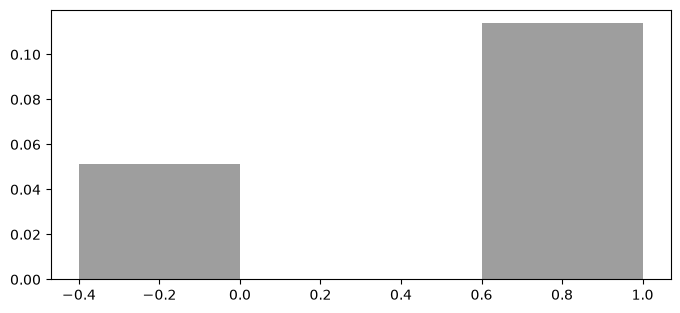

In [ ]:
# 1) İki aday ürün için desteği (genel pay) ve güveni (A'lı sepetlerdeki pay) hesapla
adaylar = ["GREEN REGENCY TEACUP AND SAUCER", "WHITE HANGING HEART T-LIGHT HOLDER"]
genel = [destek(sepet, b) for b in adaylar]
a_li = [guven(sepet, A, b) for b in adaylar]

# 2) Yan yana çubuklarla çiz
x = range(len(adaylar))
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar([i - 0.2 for i in x], genel, width=0.4, color=GRI, label="Bütün sepetlerde (destek)")
def destek(tablo, a):
    return tablo[a].mean()


def guven(tablo, a, b):
    birlikte = (tablo[a] & tablo[b]).mean()
    return birlikte / destek(tablo, a)


def kaldirac(tablo, a, b):
    return guven(tablo, a, b) / destek(tablo, b)
for i in x:
    ax.text(i + 0.2, a_li[i], f" kaldıraç {a_li[i] / genel[i]:.1f}", ha="center", va="bottom")
ax.set_xticks(list(x))
ax.set_xticklabels([b.title() for b in adaylar], fontsize=8)
ax.set_ylabel("Sepetlerin payı")
ax.set_ylim(0, max(a_li) * 1.35)
ax.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

**🔮 Düşün:** İki kuralın güvenleri birbirine yakın ama kaldıraçları çok farklı. Hangisi REGENCY CAKESTAND alan müşteri hakkında **yeni** bir şey söylüyor? Neden? Grafikteki gri çubuklar sana ne anlatıyor?

*Cevabım:* ...

<details><summary><b>🔓 Çözdükten (ya da tartıştıktan) sonra aç</b></summary>

<div style="background:#ffebee; color:#1a1a1a; border-left:6px solid #c62828; padding:10px 16px; border-radius:6px; margin:8px 0">

<b style="color:#c62828; font-size:1.05em">📌 Güven aynı, kaldıraç farklı</b>

- **WHITE HANGING HEART** zaten çok yaygın: Sepetlerin yaklaşık %11'inde var. REGENCY CAKESTAND'lı sepetlerdeki payı (%18) bundan biraz yüksek; kaldıraç yaklaşık **1,6**.
- **GREEN REGENCY TEACUP** genelde seyrek: Sepetlerin yaklaşık %5'inde var. REGENCY CAKESTAND'lı sepetlerde ise %26; yani **5 kat** daha sık.

Yeni bilgi veren kural **TEACUP** kuralı. HANGING HEART'ı önermek için müşterinin sepetine bakmaya gerek yoktu: zaten en çok satanlar listesinde. TEACUP ise REGENCY CAKESTAND alan müşteriye **özgü** bir öneri. Ürün adları da bunu destekliyor: ikisi de aynı *Regency* serisinden.

</div>

</details>

### 🕵️ İz sür: kaldıraç her zaman iyi mi?
Kaldıraç tek başına da yanıltabilir. Aşağıdaki hücre, REGENCY CAKESTAND ile kaldıracı **en yüksek** 5 ürünü buluyor (destek koşulu olmadan).

In [ ]:
sonuc = []
for b in sepet.columns:
    if b != A and (sepet[A] & sepet[b]).sum() > 0:
        sonuc.append((b, kaldirac(sepet, A, b), (sepet[A] & sepet[b]).sum()))
sonuc = pd.DataFrame(sonuc, columns=["urun", "kaldirac", "birlikte_fatura"])
sonuc.nlargest(5, "kaldirac")

**🔮 Düşün:** Listenin başındaki ürünler kaç faturada REGENCY CAKESTAND ile birlikte geçiyor? Bir ya da iki faturaya dayanan bir kurala güvenir misin?

Bütün adayları tek bir grafikte görelim. Yatay eksen: ürünün REGENCY CAKESTAND ile **kaç faturada** birlikte geçtiği (log ölçek). Dikey eksen: kaldıraç.

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(sonuc["birlikte_fatura"], sonuc["kaldirac"], s=8, alpha=0.4, color=MAVI)
ax.set_xscale("log")
ax.axhline(1, color=GRI, linestyle="--")
ax.axvline(50, color=KIRMIZI, linestyle="--")
ax.text(52, ax.get_ylim()[1] * 0.92, "50 fatura", color=KIRMIZI)
ax.set_xlabel("REGENCY CAKESTAND ile birlikte geçtiği fatura sayısı (log ölçek)")
ax.set_ylabel("Kaldıraç")
ax.set_title("Her nokta bir aday ürün")
plt.tight_layout()
plt.show()

<details><summary><b>🔓 Çözdükten (ya da tartıştıktan) sonra aç</b></summary>

<div style="background:#e3f2fd; color:#1a1a1a; border-left:6px solid #1565c0; padding:10px 16px; border-radius:6px; margin:8px 0">

<b style="color:#1565c0; font-size:1.05em">🔍 Grafiği nasıl okumalı?</b>

- Grafiğin sol üst köşesine bak: Kaldıracı yaklaşık **9,9** olan noktaların hepsi **1–4 faturalık** ürünler. Bu bir tesadüf değil, bir **tavan**: B yalnızca A'lı sepetlerde geçiyorsa güven(A→B) = destek(B) / destek(A) olur. O zaman kaldıraç = **1 / destek(A)** = 1 / 0,10 ≈ **9,9**. Tek bir ortak sepeti olan seyrek bir ürün, bu tavana kendiliğinden ulaşır.
- Sağa gidildikçe (daha çok ortak sepet) noktaların dağılımı daralıyor. Çok veriye dayanan kurallarda kaldıraç daha güvenilir.
- Kırmızı çizginin sağında kalanlar, aşağıdaki görevde seçeceğin ürünler.

Yani "**en yüksek kaldıraç**" listesinin başı, çoğu zaman "**en az veriye dayanan**" ürünlerle dolar. Bu yüzden kurallara bir **en az destek** koşulu koyarız.

</div>

</details>

**✍️ Kendin yaz:** `sonuc` tablosunu **en az 50 faturada** birlikte geçen ürünlerle sınırla ve kaldıraca göre ilk 5'i göster.

In [ ]:
# Kodunu buraya yaz

<details><summary>💡 İpucu 1</summary>

Önce maske: `sonuc["birlikte_fatura"] >= 50`. Sonra geçen haftaki `nlargest`.

</details>

<details><summary><b>🔓 Çözdükten (ya da tartıştıktan) sonra aç</b></summary>

<div style="background:#e8f5e9; color:#1a1a1a; border-left:6px solid #2e7d32; padding:10px 16px; border-radius:6px; margin:8px 0">

<b style="color:#2e7d32; font-size:1.05em">🎯 Doğru kod ve çıktı</b>

```python
sonuc[sonuc["birlikte_fatura"] >= 50].nlargest(5, "kaldirac")
```
| urun | kaldirac | birlikte_fatura |
|---|---|---|
| CHARLIE LOLA BLUE HOT WATER BOTTLE | 5,91 | 85 |
| CAKE STAND VICTORIAN FILIGREE MED | 5,71 | 74 |
| PINK BUTTERFLY HANDBAG W BOBBLES | 5,68 | 56 |
| CHARLIE+LOLA RED HOT WATER BOTTLE | 5,61 | 93 |
| REGENCY SUGAR BOWL GREEN | 5,50 | 178 |

Önce maske (`>= 50`), sonra sıralama. Liste artık 1–2 faturalık tesadüflerle değil, en az 50 faturaya dayanan ürünlerle dolu; kaldıraçlar 9,9 tavanından aşağı indi.

</div>

</details>

<div style="background:#f3e5f5; color:#1a1a1a; border-left:6px solid #6a1b9a; padding:10px 16px; border-radius:6px; margin:8px 0">

<b style="color:#6a1b9a; font-size:1.05em">🧭 Karar senin</b>

50 fatura eşiğini biz koyduk. 20 olsaydı liste değişirdi; 200 olsaydı belki hiç ürün kalmazdı. Eşik düştükçe **daha çok ama daha az güvenilir** kural; eşik yükseldikçe **daha az ama daha sağlam** kural çıkar.

Geçen hafta ülke listesi için eşik konuşmuştuk (E7). Aynı karar burada da var ve bir sonraki bölümde `min_support` adıyla karşına çıkacak.

</div>

---
## Bölüm 4: Neden Apriori? (10 dk)
Yukarıda **tek bir** ürün (A) için bütün ürünleri taradık. Bütün ürün çiftleri için yapsaydık?

**🔮 Tahmin et:** 4.000 ürün varsa kaç farklı **ikili** vardır? (İpucu: n·(n−1)/2.) Üçlüler?

*Tahminim:* ...

In [ ]:
n = sepet.shape[1]
print("İkili sayısı :", n * (n - 1) // 2)
print("Üçlü sayısı  :", n * (n - 1) * (n - 2) // 6)

Bu sayıları bir grafikte görelim. Dikey eksen **logaritmik**: her çizgi bir öncekinin 10 katı.

In [ ]:
sayilar = {"Tekli (ürün)": n, "İkili": n * (n - 1) // 2, "Üçlü": n * (n - 1) * (n - 2) // 6}
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(sayilar.keys(), sayilar.values(), color=[MAVI, TURUNCU, KIRMIZI])
ax.set_yscale("log")
ax.set_ylim(1, max(sayilar.values()) * 30)
for i, v in enumerate(sayilar.values()):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom")
ax.set_title("Sayılması gereken ürün kümesi sayısı")
plt.tight_layout()
plt.show()

<div style="background:#e8f5e9; color:#1a1a1a; border-left:6px solid #2e7d32; padding:10px 16px; border-radius:6px; margin:8px 0">

<b style="color:#2e7d32; font-size:1.05em">🎯 Ne elde ettik?</b>

4 bin ürün **8 milyon** ikili, **10 milyardan fazla** üçlü demek. Hepsini tek tek saymak, bir öneri sistemi için çok yavaş. Bize **saymadan eleyebileceğimiz** bir kural gerekiyor. Apriori'nin yaptığı tam olarak bu.

</div>

**Apriori'nin fikri tek cümle:** *Bir ürün kümesi seyrekse, onu içeren daha büyük kümeler de seyrektir.* Örneğin bir ürün sepetlerin yalnız %1'inde varsa, o ürünü içeren hiçbir ikili %1'den sık olamaz. Bu yüzden önce tekli ürünleri sayıp eşiğin altındakileri atarız; ikilileri yalnız kalanlardan kurarız; üçlüleri yalnız sık ikililerden.

Bu adımları sunumda (35. slayt) ve Excel'de (`Sunumlar/CENG468_W6_Sepet_Analizi_Excel_v2.xlsx`) 8 sepette elle yaptık. Şimdi aynısını kodla yapalım. Eşik **en az 3 sepet**:

In [ ]:
from itertools import combinations

esik = 3                                   # en az kaç sepet? (Excel'deki sarı hücre)

# Adım 1: teklileri say (Freq)
freq = sepet8.sum()
print("Freq:", freq.to_dict())

# Adım 2: eşiğin altındakileri ele
kalanlar = list(freq[freq >= esik].index)
print("Kalan tekliler:", kalanlar)
print()

# Adım 3–4: ikilileri yalnız kalanlardan kur, say, ele
for a, b in combinations(sepet8.columns, 2):
    if a in kalanlar and b in kalanlar:
        f = (sepet8[a] & sepet8[b]).sum()
        print(f"{a} · {b}: {f} sepet → {'sık' if f >= esik else 'elenir'}")
    else:
        print(f"{a} · {b}: sayılmadı (budandı)")

**Kod ne yapıyor?**
- `sepet8.sum()`: True'ları sayar; her ürünün **kaç sepette** olduğu (Freq).
- `freq[freq >= esik]`: eşiği geçen ürünler (Excel'de Adım 2).
- `combinations(sepet8.columns, 2)`: 6 üründen bütün ikililer (15 tane).
- `if a in kalanlar and b in kalanlar`: Apriori'nin budaması. İki üründen biri elendiyse ikili **hiç sayılmaz**.

**🔮 Düşün:** Eşik 3 iken kaç ikili sayıldı, kaçı sık çıktı? Peynir → Kola kuralına ne oldu?

*Cevabım:* ...

<details><summary><b>🔓 Çözdükten (ya da tartıştıktan) sonra aç</b></summary>

<div style="background:#e8f5e9; color:#1a1a1a; border-left:6px solid #2e7d32; padding:10px 16px; border-radius:6px; margin:8px 0">

<b style="color:#2e7d32; font-size:1.05em">🎯 Apriori'nin budaması (eşik 3)</b>

- Freq: Ekmek 4, Kola 4, Peynir **2**, Soğan **2**, Süt 6, Un 4. Eşik 3'te **Peynir ve Soğan elenir**.
- 15 ikiliden yalnız **6'sı sayılır** (kalan dört üründen kurulanlar); Peynir ya da Soğan içeren 9 ikili "sayılmadı (budandı)".
- Sayılan 6 ikiliden **3'ü sık**: Ekmek · Süt (3), Kola · Süt (4), Süt · Un (3). Ekmek · Kola (2), Ekmek · Un (0), Kola · Un (2) elenir.
- Üçlü aday kalmaz: her üçlünün içinde seyrek bir ikili var. Algoritma durur.
- **Bedeli:** Peynir → Kola (lift 2) bu eşikte hiç ortaya çıkmaz; Peynir birinci adımda elendi.

</div>

</details>

**🔧 Değiştir:** `esik = 2` yap ve hücreyi yeniden çalıştır. Kaç ikili sayılıyor, kaçı sık? Excel'de eşik hücresini 2 yaptığında gördüklerinle karşılaştır.

<details><summary><b>🔓 Çözdükten (ya da tartıştıktan) sonra aç</b></summary>

<div style="background:#f3e5f5; color:#1a1a1a; border-left:6px solid #6a1b9a; padding:10px 16px; border-radius:6px; margin:8px 0">

<b style="color:#6a1b9a; font-size:1.05em">🧭 Eşik 2'de ne değişti?</b>

Eşik 2'de altı ürünün **hepsi kalır**; 15 ikilinin **hepsi sayılır** ve **7'si sık**: Ekmek · Kola, Ekmek · Süt, Kola · Peynir, Kola · Süt, Peynir · Süt, Süt · Un, Kola · Un. Peynir → Kola artık bulunabilir.

Ders: eşik düştükçe daha çok küme sayılır (yavaşlar) ama daha çok kural bulunur; eşik yükseldikçe hız kazanılır ama ilginç kurallar kaybolabilir. Excel'de üçlüler de var: eşik 2'de {Ekmek, Süt, Kola}, {Un, Süt, Kola}, {Süt, Kola, Peynir} sık; dörtlü aday yok.

</div>

</details>

---
## Bölüm 5: mlxtend ile kurallar (25 dk)
Apriori'yi kendimiz yazmayacağız: `mlxtend` paketi ders ortamında kurulu. İki fonksiyon kullanacağız:
- `apriori(tablo, min_support=..., use_colnames=True)` → sık ürün kümeleri
- `association_rules(kumeler, metric="lift", min_threshold=1)` → kurallar

Hız için **Almanya** sepetleriyle başlıyoruz.

In [ ]:
from mlxtend.frequent_patterns import apriori, association_rules

# 1) Yalnızca Almanya'nın satırlarını seç
almanya = df_temiz[df_temiz["Country"] == "Germany"]

# 2) Bölüm 1'deki ilk iki adım: fatura × ürün adet tablosu
adet_tablosu = almanya.groupby(["Invoice", "Description"])["Quantity"].sum().unstack(fill_value=0)
print(adet_tablosu.shape)

**Kod ne yapıyor?** Bölüm 1'deki dönüşümün **ilk iki adımı**, bu kez yalnızca Almanya sepetleri için. Üçüncü adımı (`> 0`) bilerek yazmadık; bir sonraki hücrede neden önemli olduğunu göreceksin.

**🐞 Hata avı:** Aşağıdaki hücre hata veriyor. Hata mesajının **son satırını** oku: hangi değer bulunmuş, hangi değerler bekleniyormuş? Alttaki hücrede düzelt.

In [ ]:
kumeler = apriori(adet_tablosu, min_support=0.05, use_colnames=True)

In [ ]:
# Düzeltilmiş kod

<details><summary>💡 İpucu 1</summary>

apriori yalnız True/False (ya da 0/1) kabul ediyor. Bölüm 1'deki üçüncü adımı hatırla.

</details>

<details><summary><b>🔓 Çözdükten (ya da tartıştıktan) sonra aç</b></summary>

<div style="background:#e3f2fd; color:#1a1a1a; border-left:6px solid #1565c0; padding:10px 16px; border-radius:6px; margin:8px 0">

<b style="color:#1565c0; font-size:1.05em">🔍 Hata mesajı ne diyor, düzeltme ne?</b>

**Hatalı hücre ne verdi?** Önce sarı bir uyarı, sonra kırmızı bir hata:
```
DeprecationWarning: DataFrames with non-bool types result in worse computational performance
and their support might be discontinued in the future. Please use a DataFrame with bool type
...
ValueError: The allowed values for a DataFrame are True, False, 0, 1. Found value 12
```
**Mesajı cümle cümle okuyalım:**
- Uyarı (sarı): "True/False olmayan değerlerle çalışmak yavaştır; ileride desteklenmeyebilir; lütfen True/False tablo kullan." Bu bir ipucu, hata değil.
- Hata (kırmızı, son satır): "**Bir DataFrame için izin verilen değerler True, False, 0, 1. Bulunan değer: 12.**" Yani `apriori`, tablonun bir hücresinde **12** görmüş. 12 bir **adet**: bir faturada bir üründen 12 tane alınmış.

**Neden?** `apriori` her hücrede tek bir soru bekliyor: "bu sepette bu ürün **var mı**?" Biz ona `adet_tablosu`nu, yani "**kaç tane**?" tablosunu verdik. Bölüm 1'deki üçüncü adımı (`> 0`) yazmamıştık.

**Düzeltme:**
```python
sepet_de = adet_tablosu > 0                                    # adetleri True/False'a çevir
kumeler = apriori(sepet_de, min_support=0.05, use_colnames=True)
kumeler.sort_values("support", ascending=False).head(10)
```
**Doğru çıktının ilk satırları:**

| support | itemsets |
|---|---|
| 0,253 | frozenset({ROUND SNACK BOXES SET OF4 WOODLAND }) |
| 0,163 | frozenset({ROUND SNACK BOXES SET OF 4 FRUITS }) |
| 0,142 | frozenset({PLASTERS IN TIN WOODLAND ANIMALS}) |
| 0,142 | frozenset({REGENCY CAKESTAND 3 TIER}) |
| 0,135 | frozenset({ROUND SNACK BOXES SET OF 4 FRUITS , ROUND SNACK BOXES SET OF4 WOODLAND }) |

Excel'de bu adım Adım 0'daki var/yok tablosuydu: `EĞER(EĞERSAY(...) > 0; 1; 0)`.

</div>

</details>

**Kod ne yapıyor?** `apriori` sepet tablosundaki bütün ürünlerden ve ürün kümelerinden, desteği `min_support` eşiğini (burada %5) geçenleri bulur. `use_colnames=True` sonuçta sütun numarası yerine ürün **adını** göstermesini sağlar.

`itemsets` sütunundaki `frozenset({...})` bir **küme**: geçen haftaki `set` gibi, ama değiştirilemez. Kümede bir ürün de olabilir, iki ürün de.

**✍️ Kendin yaz:** Kaç küme tek ürünlü, kaç küme iki ürünlü? (İpucu: `kumeler["itemsets"].apply(len)` her kümenin eleman sayısını verir.)

In [ ]:
# Kodunu buraya yaz

<details><summary><b>🔓 Çözdükten (ya da tartıştıktan) sonra aç</b></summary>

<div style="background:#e8f5e9; color:#1a1a1a; border-left:6px solid #2e7d32; padding:10px 16px; border-radius:6px; margin:8px 0">

<b style="color:#2e7d32; font-size:1.05em">🎯 Doğru kod ve çıktı</b>

```python
kumeler["itemsets"].apply(len).value_counts()
```
```
itemsets
1    50
2     9
```
59 sık kümenin **50'si tek ürünlü, 9'u iki ürünlü**; üç ürünlü sık küme yok. `apply(len)` her kümenin eleman sayısını verir, `value_counts()` bu sayıları sayar.

</div>

</details>

Şimdi kurallar. `association_rules`, sık kümelerden "A → B" biçiminde kurallar üretir. `metric="lift", min_threshold=1` yalnızca kaldıracı en az 1 olan kuralları tutar: A'yı bilmenin B'yi **en azından değiştirmediği** kurallar.

In [ ]:
kurallar = association_rules(kumeler, metric="lift", min_threshold=1)
kurallar = kurallar[["antecedents", "consequents", "support", "confidence", "lift"]]
kurallar.sort_values("lift", ascending=False).head(10)

| Sütun | Türkçesi |
|---|---|
| `antecedents` | Öncül: sepette **olan** (A) |
| `consequents` | Sonuç: önerilecek (B) |
| `support` | Destek: A ve B'nin birlikte desteği, Support(A, B) |
| `confidence` | Güven: Confidence(A → B) |
| `lift` | Kaldıraç: Lift(A → B) |

**🔮 Düşün:** İlk iki satır aynı ürün çiftini ters yönde gösteriyor olabilir. Kaldıraçları aynı, güvenleri farklı. Neden? (Formüllere bak: hangisi yöne bağlı?)

<details><summary><b>🔓 Çözdükten (ya da tartıştıktan) sonra aç</b></summary>

<div style="background:#e3f2fd; color:#1a1a1a; border-left:6px solid #1565c0; padding:10px 16px; border-radius:6px; margin:8px 0">

<b style="color:#1565c0; font-size:1.05em">🔍 Hangi ölçü yöne bağlı?</b>

Formülleri birlikte destek cinsinden yazalım:

| Ölçü | Formül | A ile B yer değiştirince |
|---|---|---|
| Güven(A → B) | destek(A ve B) / **destek(A)** | Payda değişir → **farklı** |
| Kaldıraç(A → B) | destek(A ve B) / (destek(A) × destek(B)) | Payda aynı kalır → **aynı** |

Örnekte: WOODLAND CHARLOTTE BAG alanların yaklaşık **%47**'si RED RETROSPOT CHARLOTTE BAG da almış; ters yönde bu oran **%84**. Çünkü RED RETROSPOT daha seyrek: onu alanların çoğu WOODLAND'i de alıyor, ama WOODLAND alanların yarısından azı RED RETROSPOT alıyor.

**Öneri için anlamı:** Kaldıraç "bu iki ürün birbirine bağlı mı?" sorusunu, güven "**hangi yönde** önermeliyim?" sorusunu cevaplar.

</div>

</details>

Kuralları bir grafikte görelim. Her nokta bir kural: yatay eksen destek, dikey eksen güven, renk kaldıraç.

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4))
nokta = ax.scatter(kurallar["support"], kurallar["confidence"], c=kurallar["lift"],
                   cmap="viridis", s=60, edgecolor="black")
fig.colorbar(nokta, label="Kaldıraç")
ax.set_xlabel("Destek (A ve B birlikte)")
ax.set_ylabel("Güven (A → B)")
ax.set_title(f"Almanya, min_support = 0.05: {len(kurallar)} kural")
plt.tight_layout()
plt.show()

**🔍 Grafiği okurken:** Sağ üstteki kurallar hem sık (destek) hem güvenilir (güven). Renk açıldıkça kaldıraç artıyor. Bir kuralın iyi olması için **üçüne birlikte** bakmak gerekir.

**🔧 Değiştir:** `min_support` değerini 0.03 ve 0.08 yap. Küme ve kural sayısı nasıl değişiyor? Hangisini seçerdin, neden?

In [ ]:
# Kodunu buraya yaz

<details><summary><b>🔓 Çözdükten (ya da tartıştıktan) sonra aç</b></summary>

<div style="background:#f3e5f5; color:#1a1a1a; border-left:6px solid #6a1b9a; padding:10px 16px; border-radius:6px; margin:8px 0">

<b style="color:#6a1b9a; font-size:1.05em">🧭 Hangi eşik?</b>

```python
for ms in [0.03, 0.05, 0.08]:
    k = apriori(sepet_de, min_support=ms, use_colnames=True)
    r = association_rules(k, metric="lift", min_threshold=1)
    print(ms, "küme:", len(k), "kural:", len(r))
```

| `min_support` | Küme | Kural |
|---|---|---|
| 0,03 | 222 | 196 |
| 0,05 | 59 | 18 |
| 0,08 | 17 | 2 |

Eşik biraz düşünce kural sayısı **10 kattan fazla** artıyor; biraz yükselince neredeyse hiç kural kalmıyor. Almanya'da 443 sepet var: %3 eşik, bir kümenin en az **14 sepette**; %8 eşik, en az **36 sepette** görülmesi demek.

Doğru değer veriden çıkmaz. Sorulacak soru: "**Bir öneriyi kaç sepete dayandırmak bana yeterli geliyor?**" 2 kural, öneri yapmak için çok az; 196 kuralın bir kısmı ise birkaç sepetlik tesadüf olabilir.

</div>

</details>

---
## Bölüm 6: Kuraldan öneriye (20 dk)
Bir müşterinin sepetinde şu ürünler var. Kurallara bakarak ona ne önerirsin?

In [ ]:
musteri_sepeti = {"PLASTERS IN TIN WOODLAND ANIMALS"}

> ⚠️ Bazı ürün adlarının **sonunda boşluk** var (`"ROUND SNACK BOXES SET OF 4 FRUITS "`). Adı elle yazarsan eşleşmez. Bu, verinin kirliliğinin bir parçası; ileride `.str.strip()` ile temizleyebiliriz. Aşağıda bunu bir görevde göreceksin.

**Plan:**
1. Öncülü (`antecedents`) müşterinin sepetinin **alt kümesi** olan kuralları seç. (`küme1 <= küme2`: küme1'in her elemanı küme2'de mi?)
2. Sonuçları (`consequents`) topla; müşterinin zaten aldıklarını çıkar.
3. Kaldıraca göre sırala, ilk `n` taneyi öner.

**🔮 Tahmin et:** `{"a"} <= {"a", "b"}` ve `{"a", "c"} <= {"a", "b"}` ne verir?

In [ ]:
print({"a"} <= {"a", "b"})
print({"a", "c"} <= {"a", "b"})

<div style="background:#e3f2fd; color:#1a1a1a; border-left:6px solid #1565c0; padding:10px 16px; border-radius:6px; margin:8px 0">

<b style="color:#1565c0; font-size:1.05em">🔍 Nasıl düşünmeli?</b>

Fonksiyonu yazmadan önce planı **küçük bir örnekte elle** uygula. Müşterinin sepeti {Kalem, Defter} olsun ve üç kuralımız olsun:

| Kural | Öncül müşterinin sepetinde mi? | Önerilir mi? |
|---|---|---|
| {Kalem} → {Silgi} | ✅ {Kalem} ⊆ {Kalem, Defter} | ✅ Silgi |
| {Defter} → {Kalem} | ✅ | ❌ Kalem zaten sepette |
| {Cetvel} → {Pergel} | ❌ Cetvel sepette yok | ❌ |

Fonksiyonun yapacağı iş tam olarak bu tablo: **her kural için iki soru**.

</div>

**✍️ Kendin yaz:** Planı bir fonksiyona çevir. İskelet hazır; boşlukları doldur.

In [ ]:
def sepete_oner(kurallar, sepet_kumesi, n=5):
    uygun = kurallar[kurallar["antecedents"].apply(lambda a: a <= ___)]
    oneriler = {}
    for _, kural in uygun.iterrows():
        for urun in kural["consequents"]:
            if urun not in ___:
                oneriler[urun] = max(oneriler.get(urun, 0), kural["lift"])
    return pd.Series(oneriler).sort_values(ascending=False).head(n)


sepete_oner(kurallar, musteri_sepeti)

<details><summary>💡 İpucu 1</summary>

İki boşluk da aynı değişkeni bekliyor: müşterinin sepeti.

</details>

<details><summary>💡 İpucu 2</summary>

`oneriler.get(urun, 0)` sözlükte ürün yoksa 0 döndürür (geçen haftaki KeyError'ın çaresi).

</details>

<details><summary><b>🔓 Çözdükten (ya da tartıştıktan) sonra aç</b></summary>

<div style="background:#e3f2fd; color:#1a1a1a; border-left:6px solid #1565c0; padding:10px 16px; border-radius:6px; margin:8px 0">

<b style="color:#1565c0; font-size:1.05em">🔍 Bir çözüm, adım etiketleriyle</b>

```python
def sepete_oner(kurallar, sepet_kumesi, n=5):
    # 1) Öncülü müşterinin sepetinde olan kuralları seç
    uygun = kurallar[kurallar["antecedents"].apply(lambda a: a <= sepet_kumesi)]
    # 2) Her uygun kuralın sonucundaki ürünleri topla
    oneriler = {}
    for _, kural in uygun.iterrows():
        for urun in kural["consequents"]:
            if urun not in sepet_kumesi:                                        # zaten aldığını önerme
                oneriler[urun] = max(oneriler.get(urun, 0), kural["lift"])     # en yüksek kaldıracı tut
    # 3) Kaldıraca göre sırala, ilk n taneyi döndür
    return pd.Series(oneriler).sort_values(ascending=False).head(n)
```
- **`.apply(lambda a: ...)`**: `antecedents` sütunundaki her kümeye aynı soruyu sorar: "bu küme müşterinin sepetinin alt kümesi mi?" Sonuç bir maske.
- **`iterrows()`**: Tablonun satırlarını tek tek dolaşır. `_` index'i, `kural` satırın kendisi.
- **`max(...)`**: Aynı ürün birden çok kuralın sonucunda çıkabilir. Hangisinin kaldıracı büyükse onu tutuyoruz.

Doğru çıktı (sunumdaki 47–48. slayt):
```
PLASTERS IN TIN CIRCUS PARADE          4.112908
PLASTERS IN TIN SPACEBOY               4.018141
ROUND SNACK BOXES SET OF4 WOODLAND     2.134637
```
Müşteriye aynı yara bandı serisinin başka desenleri ve sık birlikte alınan bir ürün öneriliyor. `NameError: name '___' is not defined` görüyorsan boşlukları doldurmamışsındır.

</div>

</details>

**🔧 Değiştir:** Müşterinin sepetine **ROUND SNACK BOXES SET OF 4 FRUITS** ekle. Önce adı **sonunda boşluk olmadan** yaz, sonra **sonunda bir boşlukla** (`"ROUND SNACK BOXES SET OF 4 FRUITS "`). İki çıktı arasında ne fark var? Neden?

In [ ]:
# Kodunu buraya yaz

<details><summary><b>🔓 Çözdükten (ya da tartıştıktan) sonra aç</b></summary>

<div style="background:#fff3e0; color:#1a1a1a; border-left:6px solid #ef6c00; padding:10px 16px; border-radius:6px; margin:8px 0">

<b style="color:#ef6c00; font-size:1.05em">⚠️ Sondaki boşluk</b>

```
# boşluksuz                                    # boşluklu
PLASTERS IN TIN CIRCUS PARADE      4.112908    PLASTERS IN TIN CIRCUS PARADE      4.112908
PLASTERS IN TIN SPACEBOY           4.018141    PLASTERS IN TIN SPACEBOY           4.018141
ROUND SNACK BOXES SET OF4 WOODLAND 2.134637    ROUND SNACK BOXES SET OF4 WOODLAND 3.296131
```
**Boşluksuz yazınca hiçbir şey değişmedi.** Veride ürünün adı sonunda bir boşlukla geçiyor; boşluksuz ad hiçbir kuralın öncülüyle eşleşmedi, fonksiyon bu ürünü yok saydı. Hata da vermedi: sessizce yanlış sonuç, en tehlikeli hata türü.

**Boşluklu yazınca** {ROUND SNACK BOXES SET OF 4 FRUITS } → {ROUND SNACK BOXES SET OF4 WOODLAND } kuralı (lift 3,30) devreye girdi; aynı ürün için daha yüksek kaldıracı tuttuğumuz için 2,13 yerine 3,30 göründü.

</div>

</details>

**🔮 Tahmin et:** Sepeti kurallarda hiç geçmeyen bir ürün olan müşteriye fonksiyon ne döndürür?

*Tahminim:* ...

In [ ]:
sepete_oner(kurallar, {"WHITE HANGING HEART T-LIGHT HOLDER"})

<details><summary><b>🔓 Çözdükten (ya da tartıştıktan) sonra aç</b></summary>

<div style="background:#e8f5e9; color:#1a1a1a; border-left:6px solid #2e7d32; padding:10px 16px; border-radius:6px; margin:8px 0">

<b style="color:#2e7d32; font-size:1.05em">🎯 Tahminini kontrol et</b>

**Boş bir Series:** `Series([], dtype: object)`. Almanya kurallarında WHITE HANGING HEART hiçbir kuralın öncülü değil (Almanya'da %5 desteğe ulaşmıyor). Fonksiyon hata vermiyor ama müşteriye **hiçbir şey önermiyor**. Buna **soğuk başlangıç** denir; bir sonraki görev bunu çözüyor.

</div>

</details>

**🔧 Değiştir (soğuk başlangıç, geçen haftaki gibi):** Kural bulunamazsa fonksiyon boş liste yerine **ülkenin en çok satanlarını** döndürsün.

In [ ]:
# Kodunu buraya yaz

<details><summary>💡 İpucu 1</summary>

Geçen haftaki `en_cok_satan` fonksiyonunu hatırla. Almanya için fatura sayısına göre sıralı listeyi `yedek` olarak ver.

</details>

<details><summary><b>🔓 Çözdükten (ya da tartıştıktan) sonra aç</b></summary>

<div style="background:#e3f2fd; color:#1a1a1a; border-left:6px solid #1565c0; padding:10px 16px; border-radius:6px; margin:8px 0">

<b style="color:#1565c0; font-size:1.05em">🔍 Doğru kod ve çıktı</b>

```python
def sepete_oner(kurallar, sepet_kumesi, n=5, yedek=None):
    uygun = kurallar[kurallar["antecedents"].apply(lambda a: a <= sepet_kumesi)]
    oneriler = {}
    for _, kural in uygun.iterrows():
        for urun in kural["consequents"]:
            if urun not in sepet_kumesi:
                oneriler[urun] = max(oneriler.get(urun, 0), kural["lift"])
    if len(oneriler) == 0 and yedek is not None:                    # kural yoksa
        return yedek.drop(list(sepet_kumesi), errors="ignore").head(n)   # yedek listeye dön
    return pd.Series(oneriler).sort_values(ascending=False).head(n)


en_cok_satan_de = almanya.groupby("Description")["Invoice"].nunique().sort_values(ascending=False)
sepete_oner(kurallar, {"WHITE HANGING HEART T-LIGHT HOLDER"}, yedek=en_cok_satan_de)
```
```
ROUND SNACK BOXES SET OF4 WOODLAND     112
ROUND SNACK BOXES SET OF 4 FRUITS       72
PLASTERS IN TIN WOODLAND ANIMALS        63
REGENCY CAKESTAND 3 TIER                63
WOODLAND CHARLOTTE BAG                  58
```
Yeni olan iki satır: `yedek=None` parametresi ve `if len(oneriler) == 0 ...`. Sayılar artık kaldıraç değil, **fatura sayısı** (geçen haftanın listesi). `drop(..., errors="ignore")` müşterinin zaten aldığı ürünü listeden çıkarır; ürün listede yoksa hata vermez.

</div>

</details>

<div style="background:#ffebee; color:#1a1a1a; border-left:6px solid #c62828; padding:10px 16px; border-radius:6px; margin:8px 0">

<b style="color:#c62828; font-size:1.05em">📌 Asıl ders</b>

Bugün kurduğumuz öneri sistemi iki katmanlı:

1. **Sepete bakan katman:** Müşterinin sepetindeki ürünlerle eşleşen kural varsa, kuralların önerisini kullan.
2. **Yedek katman:** Kural yoksa geçen haftanın **en çok satanlar** listesine dön.

Gerçek öneri sistemleri de böyle çalışır: Kişiye özgü bilgi varsa onu kullanır, yoksa herkese uyan bir listeye döner. Geçen haftaki liste çöpe gitmedi; **sistemin güvenlik ağı** oldu.

</div>

---
#### ⭐ Ek alıştırmalar: erken bitirenler ve ev için
**E1.** Aynı adımları **Fransa** için tekrarla (`min_support=0.05`). Kaldıracı en yüksek 5 kural hangileri? Almanya'dakilerle benzer mi?

In [ ]:
# E1

<details><summary><b>🔓 Çözdükten (ya da tartıştıktan) sonra aç</b></summary>

<div style="background:#e8f5e9; color:#1a1a1a; border-left:6px solid #2e7d32; padding:10px 16px; border-radius:6px; margin:8px 0">

<b style="color:#2e7d32; font-size:1.05em">🎯 E1: sonuç</b>

Fransa: 382 fatura × 1.561 ürün, 86 kural. Kaldıracı en yüksek kurallar:

| Öncül | Sonuç | Güven | Kaldıraç |
|---|---|---|---|
| PACK OF 6 SKULL PAPER CUPS | PACK OF 6 SKULL PAPER PLATES | 0,80 | 13,9 |
| PACK OF 6 SKULL PAPER PLATES | PACK OF 6 SKULL PAPER CUPS | 0,91 | 13,9 |
| CHILDRENS CUTLERY SPACEBOY | CHILDRENS CUTLERY DOLLY GIRL | 0,93 | 12,6 |
| CHILDRENS CUTLERY DOLLY GIRL | CHILDRENS CUTLERY SPACEBOY | 0,89 | 12,6 |
| ALARM CLOCK BAKELIKE RED | ALARM CLOCK BAKELIKE PINK, ALARM CLOCK BAKELIKE GREEN | 0,68 | 8,9 |

Ürünler Almanya'dakinden farklı ama desen aynı: aynı ürünün eşi ya da başka rengi.

</div>

</details>

**E2.** Fransa'nın en yüksek kaldıraçlı kurallarında hep **aynı ürünün farklı renkleri ya da desenleri** mi var? Böyle bir kuralı öneri olarak göstermek mağazaya bir şey kazandırır mı?

<details><summary><b>🔓 Çözdükten (ya da tartıştıktan) sonra aç</b></summary>

<div style="background:#f3e5f5; color:#1a1a1a; border-left:6px solid #6a1b9a; padding:10px 16px; border-radius:6px; margin:8px 0">

<b style="color:#6a1b9a; font-size:1.05em">🧭 E2: tartışma</b>

Evet, çoğu aynı ürünün eşi, rengi ya da deseni (tabak–bardak, kız–erkek çatal takımı, saat renkleri). Mağaza açısından katkısı sınırlı: müşteri bu eşleşmeyi rafta zaten görüyor. İstatistiksel güç, iş değeri demek değil (sunumda 44. slayt, "sıradan kural").

</div>

</details>

**E3.** Bütün veride (bütün ülkeler) `min_support=0.02` ile kaç kural çıkıyor? Kaldıracı en yüksek 5 kural hangileri? (Uyarı: tablo büyük; birkaç saniye sürer.)

In [ ]:
# E3

<details><summary><b>🔓 Çözdükten (ya da tartıştıktan) sonra aç</b></summary>

<div style="background:#e8f5e9; color:#1a1a1a; border-left:6px solid #2e7d32; padding:10px 16px; border-radius:6px; margin:8px 0">

<b style="color:#2e7d32; font-size:1.05em">🎯 E3: sonuç</b>

Bütün veride `min_support=0.02` ile **176 kural**. En üstte REGENCY TEACUP AND SAUCER renkleri (PINK, ROSES, GREEN) var; kaldıraç yaklaşık **16–18**. Örneğin {PINK REGENCY TEACUP AND SAUCER} → {ROSES REGENCY TEACUP AND SAUCER , GREEN REGENCY TEACUP AND SAUCER}: güven 0,71, kaldıraç 18,2.

Uyarı: bütün veride eşiği 0,02'nin altına indirme; 0,01'de bellek yetmeyebilir.

</div>

</details>

---
### 🧠 Kendini sına (5 soru)
Önce cevabını **yaz**, sonra alttaki hücreyi çalıştırıp kontrol et.

1. 100 sepetin 60'ında X, 40'ında Y, 30'unda X ve Y birlikte var. destek(X), güven(X → Y), kaldıraç(X → Y) kaç?
2. Aynı veride güven(Y → X) kaç? Kaldıraç(Y → X) kaç?
3. Kaldıracı 1 olan bir kural ne söyler?
4. `apriori` neden adet tablosuyla değil True/False tablosuyla çalışır? (İki sebep.)
5. `{"Çay"} <= {"Çay", "Süt"}` ne verir? Bu, sepete_oner fonksiyonunda neyi kontrol ediyor?

*Cevaplarım:*
1. ...
2. ...
3. ...
4. ...
5. ...

In [ ]:
dX, dY, dXY = 60 / 100, 40 / 100, 30 / 100
print(1, dX, round(dXY / dX, 2), round((dXY / dX) / dY, 2))
print(2, round(dXY / dY, 2), round((dXY / dY) / dX, 2))
print(5, {"Çay"} <= {"Çay", "Süt"})

<details><summary><b>🔓 Çözdükten (ya da tartıştıktan) sonra aç</b></summary>

<div style="background:#e8f5e9; color:#1a1a1a; border-left:6px solid #2e7d32; padding:10px 16px; border-radius:6px; margin:8px 0">

<b style="color:#2e7d32; font-size:1.05em">🎯 Kendini sına: cevaplar</b>

1. Support(X) = 60/100 = **0,60** · Confidence(X → Y) = 30/60 = **0,50** · Lift(X → Y) = 0,50 / 0,40 = **1,25** (sunumda 22–25. slayt).
2. Confidence(Y → X) = 30/40 = **0,75** · Lift(Y → X) = 0,75 / 0,60 = **1,25**. Güven yöne bağlı, kaldıraç simetrik.
3. A ile B **bağımsız**: A'nın varlığı B olasılığını değiştirmiyor; kural yeni bilgi vermiyor (çoğu zaman B zaten popüler).
4. (a) Soru "kaç tane?" değil "**var mı?**"; (b) `apriori` yalnız True/False ya da 0/1 kabul ediyor (Bölüm 5'teki ValueError). Ek: dev bir siparişin (PAPER CRAFT) sonucu bozmasını önler.
5. **True.** `sepete_oner`, kuralın öncülünün müşterinin sepetinde **tamamen** bulunup bulunmadığını bu işlemle kontrol ediyor.

</div>

</details>

---
## Kapanış
**Bugün:** Satırları sepetlere çevirdik; destek, güven ve kaldıracı önce elle, sonra `mlxtend` ile hesapladık; kurallardan bir öneri fonksiyonu yazdık.

**Üç ders:**
1. Güven yüksek diye kural iyi değildir: popüler ürün her kuralın sonucunda çıkar (kaldıraç ≈ 1).
2. Kaldıraç yüksek diye kural iyi değildir: bir iki faturaya dayanıyorsa tesadüf olabilir (en az destek).
3. Eşikleri (destek, güven, kaldıraç) veri değil, **sen** seçersin; gerekçesini yazarsın.

**Haftaya kadar:**
1. Boş bıraktığın ✍️, 🔧 ve 🐞 hücrelerini tamamla.
2. Bölüm 5'teki `min_support` seçimini ve gerekçeni yaz.
3. Kendini sına sorularını cevapla; vaktin olursa E1–E3.

---
## 📚 Başvuru: Bu defterde neyi nerede yaptık?
"Bunu bir yerde yapmıştık" diye arıyorsan önce buraya bak.

<table>
<tr style="background:#37474f; color:#ffffff"><th>Ne yapmak istiyorum?</th><th>Kod kalıbı</th><th>Nerede?</th></tr>

<tr style="background:#1565c0; color:#ffffff"><td colspan="3"><b>🧺 Sepet tablosu kurmak</b></td></tr>
<tr style="background:#e3f2fd; color:#1a1a1a"><td>İki sütuna göre gruplamak</td><td><code>df.groupby(["Invoice", "Description"])["Quantity"].sum()</code></td><td>Bölüm 1</td></tr>
<tr style="background:#e3f2fd; color:#1a1a1a"><td>Uzun tabloyu genişe çevirmek</td><td><code>.unstack(fill_value=0)</code></td><td>Bölüm 1</td></tr>
<tr style="background:#e3f2fd; color:#1a1a1a"><td>Adetten "var mı?"ya geçmek</td><td><code>tablo &gt; 0</code></td><td>Bölüm 1, 5</td></tr>
<tr style="background:#e3f2fd; color:#1a1a1a"><td>Tablonun ne kadarı dolu?</td><td><code>sepet.values.mean()</code></td><td>Bölüm 1</td></tr>

<tr style="background:#2e7d32; color:#ffffff"><td colspan="3"><b>📏 Ölçüleri hesaplamak</b></td></tr>
<tr style="background:#e8f5e9; color:#1a1a1a"><td>Destek (support)</td><td><code>tablo[a].mean()</code></td><td>Bölüm 2</td></tr>
<tr style="background:#e8f5e9; color:#1a1a1a"><td>İki ürün birlikte</td><td><code>(tablo[a] &amp; tablo[b]).mean()</code></td><td>Bölüm 2</td></tr>
<tr style="background:#e8f5e9; color:#1a1a1a"><td>Elle Apriori budaması</td><td><code>combinations(...)</code> · <code>if a in kalanlar and b in kalanlar</code></td><td>Bölüm 4</td></tr>
<tr style="background:#e8f5e9; color:#1a1a1a"><td>Güven (confidence), kaldıraç (lift)</td><td><code>guven(tablo, a, b)</code> · <code>kaldirac(tablo, a, b)</code></td><td>Bölüm 2, 3</td></tr>

<tr style="background:#ef6c00; color:#ffffff"><td colspan="3"><b>⚙️ mlxtend ile kurallar</b></td></tr>
<tr style="background:#fff3e0; color:#1a1a1a"><td>Sık ürün kümeleri</td><td><code>apriori(tablo, min_support=0.05, use_colnames=True)</code></td><td>Bölüm 5</td></tr>
<tr style="background:#fff3e0; color:#1a1a1a"><td>Kurallar</td><td><code>association_rules(kumeler, metric="lift", min_threshold=1)</code></td><td>Bölüm 5</td></tr>
<tr style="background:#fff3e0; color:#1a1a1a"><td>Kümelerin boyu</td><td><code>kumeler["itemsets"].apply(len)</code></td><td>Bölüm 5</td></tr>

<tr style="background:#6a1b9a; color:#ffffff"><td colspan="3"><b>🎁 Öneri</b></td></tr>
<tr style="background:#f3e5f5; color:#1a1a1a"><td>Alt küme mi?</td><td><code>{"a"} &lt;= {"a", "b"}</code></td><td>Bölüm 6</td></tr>
<tr style="background:#f3e5f5; color:#1a1a1a"><td>Her elemana aynı soruyu sormak</td><td><code>seri.apply(lambda a: ...)</code></td><td>Bölüm 6</td></tr>
<tr style="background:#f3e5f5; color:#1a1a1a"><td>Satırları tek tek dolaşmak</td><td><code>for _, satir in tablo.iterrows():</code></td><td>Bölüm 6</td></tr>
<tr style="background:#f3e5f5; color:#1a1a1a"><td>Sözlükte yoksa varsayılan değer</td><td><code>sozluk.get(anahtar, 0)</code></td><td>Bölüm 6</td></tr>

<tr style="background:#455a64; color:#ffffff"><td colspan="3"><b>🖼️ Grafik</b></td></tr>
<tr style="background:#eceff1; color:#1a1a1a"><td>Seyrek bir tabloyu görmek</td><td><code>ax.imshow(tablo.values, cmap="Blues")</code></td><td>Bölüm 1</td></tr>
<tr style="background:#eceff1; color:#1a1a1a"><td>İki ölçünün ilişkisi, renk üçüncü ölçü</td><td><code>ax.scatter(x, y, c=renk_degeri)</code></td><td>Bölüm 3, 5</td></tr>
</table>

<div style="background:#ffebee; color:#1a1a1a; border-left:6px solid #c62828; padding:10px 16px; border-radius:6px; margin:8px 0">

<b style="color:#c62828; font-size:1.05em">📌 Bugünün dersleri</b>

| | Ders | Nerede? |
|---|---|---|
| 1 | **Sepet analizinin birimi faturadır.** Tabloyu "sepet × ürün" biçimine çevir; adet değil, **var mı?** | Bölüm 1 |
| 2 | **Güven yüksek diye kural iyi değildir.** Popüler ürün her kuralın sonucunda çıkar; kaldıraca bak. | Bölüm 2, 3 |
| 3 | **Kaldıraç yüksek diye kural iyi değildir.** Bir iki sepete dayanan kural tesadüf olabilir; en az destek koy. | Bölüm 3 |
| 4 | **Güven yöne bağlıdır, kaldıraç değildir.** Hangi yönde önereceğini güven söyler. | Bölüm 5 |
| 5 | **Eşikleri veri değil, sen seçersin.** Gerekçesini yaz. | Bölüm 3, 5 |
| 6 | **Kural yoksa yedek liste.** Kişiselleştirilmemiş liste, sistemin güvenlik ağıdır. | Bölüm 6 |

</div>